In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import scipy.optimize
from scipy.optimize import minimize
from scipy.stats import norm
from scipy.special import logsumexp
import warnings
from scipy.optimize import curve_fit
from scipy.optimize import approx_fprime
import scipy.stats as stats
from pybads import BADS

from matplotlib.colors import LinearSegmentedColormap

# TEMP
warnings.simplefilter("ignore", category=FutureWarning)

from src.src import *

# Set some defaults
plt.rc("axes.spines", top=False, right=False)
plt.rcParams["mathtext.default"] = "regular"
sns.set_theme(font_scale=1.2)
sns.set_style("ticks")
# sns.set_palette('deep')

%config InlineBackend.figure_format = "retina"

In [2]:
# Helper functions
def converter(input_str):
    return np.fromstring(input_str[1:-1], sep=' ')


def plot_individual(df, ege, ige, adaptation, color="k", title=None):
    fig, axs = plt.subplots(1, 2, figsize=(8, 4))
    sns.regplot(data=df, x=ege, x_jitter=0.1, y=adaptation, lowess=True,
               scatter_kws={"alpha":0.15, "color":"gray"},  line_kws={"color":color}, ax=axs[0])
    axs[0].set(xlabel="EGE ($\degree$)", ylabel="Adaptation ($\degree$)", 
               xlim=[-10.5, 10.5], xticks=np.arange(-10, 10.01, 2), ylim=[-12, 12], 
               yticks=np.arange(-10, 10.01, 2))
    axs[0].axhline(color="k", linewidth=0.5)

    sns.regplot(data=df, x=ige, y=adaptation, line_kws={"color":color}, lowess=False,
                scatter_kws={"alpha":0.4, "color":"gray"}, ax=axs[1])
    axs[1].set(ylim=[-12, 12], yticks=np.arange(-10, 10.01, 2), xlim=[-10.5, 10.5], 
               xticks=np.arange(-10, 10.01, 2), xlabel="IGE ($\degree$)", 
               ylabel="Adaptation ($\degree$)")
    axs[1].axhline(color="k", linewidth=0.5)
    sns.despine()
    fig.suptitle(title, y=0.90)
    plt.tight_layout()
    
    return fig


def calc_sse(x, y):   
    return np.sum((x - y)**2)

In [3]:
# Read in data
fits_unified = pd.read_csv("model-fits/simult-vs-sep.csv", converters={"params": converter})
fits_adapt = pd.read_csv("model-fits/fits_adapt.csv", converters={"params": converter})
fits_sdt = pd.read_csv("model-fits/fits_sdt.csv", converters={"params": converter})
fits_unified.head()

,SN,model,fit_task,nll,aic,bic,params,C,B,sigma_v,b,sigma_comb,alpha,beta,sigma_p,sigma_pert,aic_diff_piece
0,1,vco,both,1.424032,6637.293561,6657.428238,"[3.57232811, 0.25478522, 2.51053578, 1.32231413]",3.572328,0.254785,2.510536,1.322314,NaN,NaN,NaN,NaN,NaN,NaN
1,2,vco,both,1.362104,6354.405311,6374.542993,"[5.48721453, 0.21305517, 2.60325284, 2.00097876]",5.487215,0.213055,2.603253,2.000979,NaN,NaN,NaN,NaN,NaN,NaN
2,3,vco,both,1.607823,6988.165839,7008.056140,"[4.3539804, 0.29277927, 5.54335254, 0.28008898]",4.353980,0.292779,5.543353,0.280089,NaN,NaN,NaN,NaN,NaN,NaN
3,4,vco,both,1.535363,7131.082204,7151.204832,"[5.01406813, 0.25498197, 3.84009646, -0.81954122]",5.014068,0.254982,3.840096,-0.819541,NaN,NaN,NaN,NaN,NaN,NaN
4,5,vco,both,1.370465,6387.885847,6408.020524,"[5.56814739, 0.36519637, 3.18622615, 0.89385385]",5.568147,0.365196,3.186226,0.893854,NaN,NaN,NaN,NaN,NaN,NaN


/var/folders/42/fy648srd41l966jbjlswhljc0000gr/T/ipykernel_75328/1841367957.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set(xlabel="Model", xticklabels=["VCO", "CO"], ylabel="$\Delta$ AIC", ylim=[-500, 500])


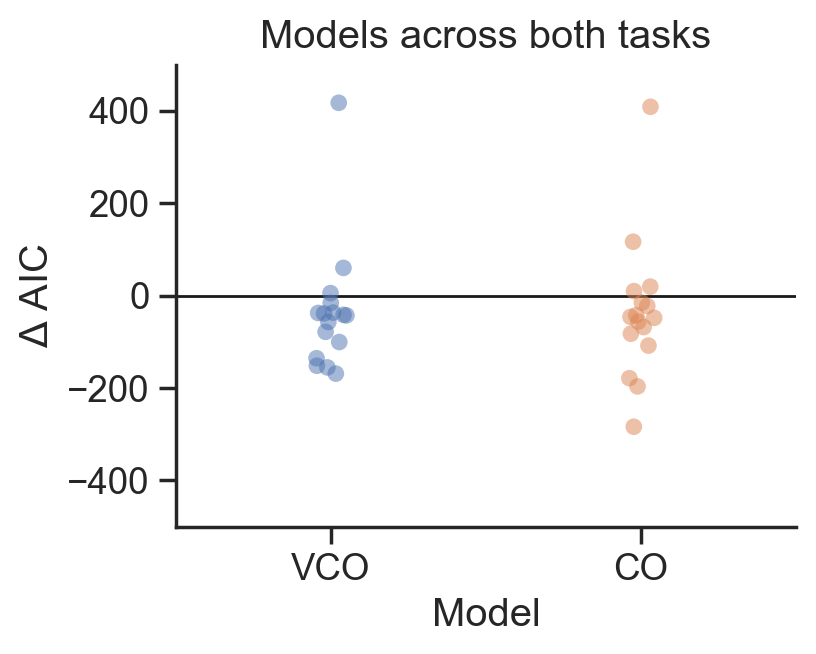

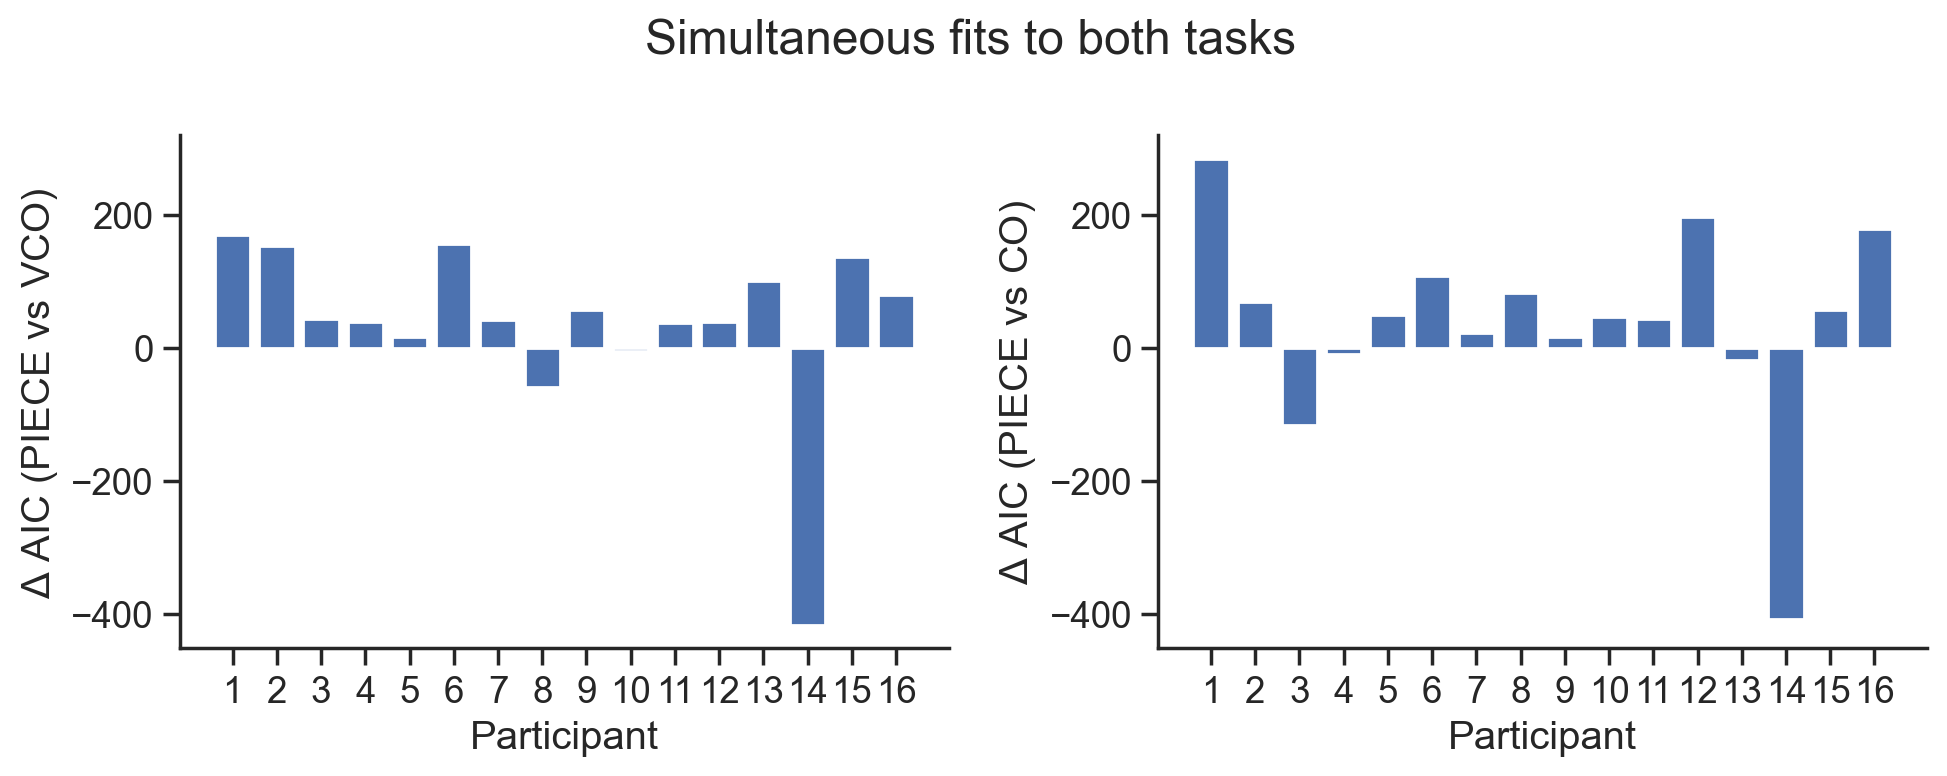

In [4]:
# Compare models on adaptation task
idx_vco = (fits_unified["model"] == "vco") 
idx_co = (fits_unified["model"] == "co") 
idx_piece = (fits_unified["model"] == "piece") 

# Compare simultaneous fits vs separate across both tasks
fig, ax = plt.subplots(figsize=(4, 3))
sns.stripplot(data=fits_unified, x="model", y="aic_diff_piece", size=6, alpha=0.5, 
              jitter=0.05, hue="model", ax=ax, order=["vco", "co"])
ax.axhline(color="k", linewidth=1.0)
ax.set(xlabel="Model", xticklabels=["VCO", "CO"], ylabel="$\Delta$ AIC", ylim=[-500, 500])
ax.set_title("Models across both tasks")
sns.despine()
plt.show()

# Compare simultaneous fits vs separate across both tasks
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
ax1.bar(x=fits_unified.loc[idx_vco, "SN"].values, height=fits_unified.loc[idx_vco, "aic_diff_piece"].values * -1)
ax2.bar(x=fits_unified.loc[idx_vco, "SN"].values, height=fits_unified.loc[idx_co, "aic_diff_piece"].values * -1)
ax1.set(xticks=np.arange(1, 17), ylabel="$\Delta$ AIC (PIECE vs VCO)", xlabel="Participant")
ax2.set(ylabel="$\Delta$ AIC (PIECE vs CO)", xlabel="Participant")
ax2.tick_params(labelleft=True)
fig.suptitle("Simultaneous fits to both tasks")
sns.despine()
plt.tight_layout()

In [5]:
# Who's the outlier?
fits_unified.groupby(["SN", "model"])["aic_diff_piece"].mean()

SN  model
1   co      -284.028062
    piece      0.000000
    vco     -169.061877
2   co       -68.338717
    piece      0.000000
    vco     -152.068076
3   co       116.368683
    piece      0.000000
    vco      -43.090376
4   co         9.508951
    piece      0.000000
    vco      -37.823236
5   co       -48.332440
    piece      0.000000
    vco      -16.179791
6   co      -108.455794
    piece      0.000000
    vco     -155.643991
7   co       -22.692476
    piece      0.000000
    vco      -41.921824
8   co       -82.610688
    piece      0.000000
    vco       59.725405
9   co       -15.398713
    piece      0.000000
    vco      -57.308567
10  co       -46.283652
    piece      0.000000
    vco        5.169298
11  co       -42.639581
    piece      0.000000
    vco      -37.005988
12  co      -196.786538
    piece      0.000000
    vco      -38.815628
13  co        19.199330
    piece      0.000000
    vco     -100.669525
14  co       408.476503
    piece      0.000000
    vc

In [6]:
# Compare models on adaptation task
idx_vco = (fits_adapt["model"] == "vco") 
idx_co = (fits_adapt["model"] == "co") 
idx_piece = (fits_adapt["model"] == "piece") 

# Compare models to PIECE using scaled AICs
diff_vco = fits_adapt.loc[idx_piece, "aic_weighted"].values - fits_adapt.loc[idx_vco, "aic_weighted"].values
diff_co = fits_adapt.loc[idx_piece, "aic_weighted"].values - fits_adapt.loc[idx_co, "aic_weighted"].values
diff_piece = fits_adapt.loc[idx_piece, "aic_weighted"].values - fits_adapt.loc[idx_piece, "aic_weighted"].values

fits_adapt["aic_diff_piece"] = np.nan
fits_adapt.loc[idx_vco, "aic_diff_piece"] = diff_vco
fits_adapt.loc[idx_co, "aic_diff_piece"] = diff_co
fits_adapt.loc[idx_piece, "aic_diff_piece"] = diff_piece
fits_adapt.head()

,SN,model,fit_task,nll,aic,bic,params,C,B,sigma_v,b,sigma_comb,alpha,beta,sigma_p,sigma_pert,aic_weighted,bic_weighted,aic_diff_piece
0,1,vco,adapt,3585.543747,7179.087493,7200.419586,"[6.61323248, 0.27264688, 4.68736999, 1.6668171]",6.613232,0.272647,4.687370,1.666817,NaN,NaN,NaN,NaN,NaN,5463.650877,5483.889348,-109.138060
1,2,vco,adapt,3599.560440,7207.120880,7228.458197,"[5.72725547, 0.22376168, 2.04734466, 1.83265629]",5.727255,0.223762,2.047345,1.832656,NaN,NaN,NaN,NaN,NaN,5482.527301,5502.769206,-104.551770
2,3,vco,adapt,3599.262746,7206.525492,7227.485222,"[10.0, 0.22018826, 9.90201301, 0.33750882]",10.000000,0.220188,9.902013,0.337509,NaN,NaN,NaN,NaN,NaN,5613.451522,5633.410706,-106.440120
3,4,vco,adapt,3805.929443,7619.858885,7641.167378,"[9.99999718, 0.21679713, 9.99999748, -0.87884907]",9.999997,0.216797,9.999997,-0.878849,NaN,NaN,NaN,NaN,NaN,5813.230971,5833.455672,23.591730
4,5,vco,adapt,3579.280940,7166.561881,7187.893973,"[7.24728977, 0.26187058, 7.04234385, 0.95856945]",7.247290,0.261871,7.042344,0.958569,NaN,NaN,NaN,NaN,NaN,5454.121588,5474.360058,-9.189779


/var/folders/42/fy648srd41l966jbjlswhljc0000gr/T/ipykernel_75328/1151407869.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set(xlabel="Model", xticklabels=["VCO", "CO"], ylabel="$\Delta$ AIC", ylim=[-400, 1000])


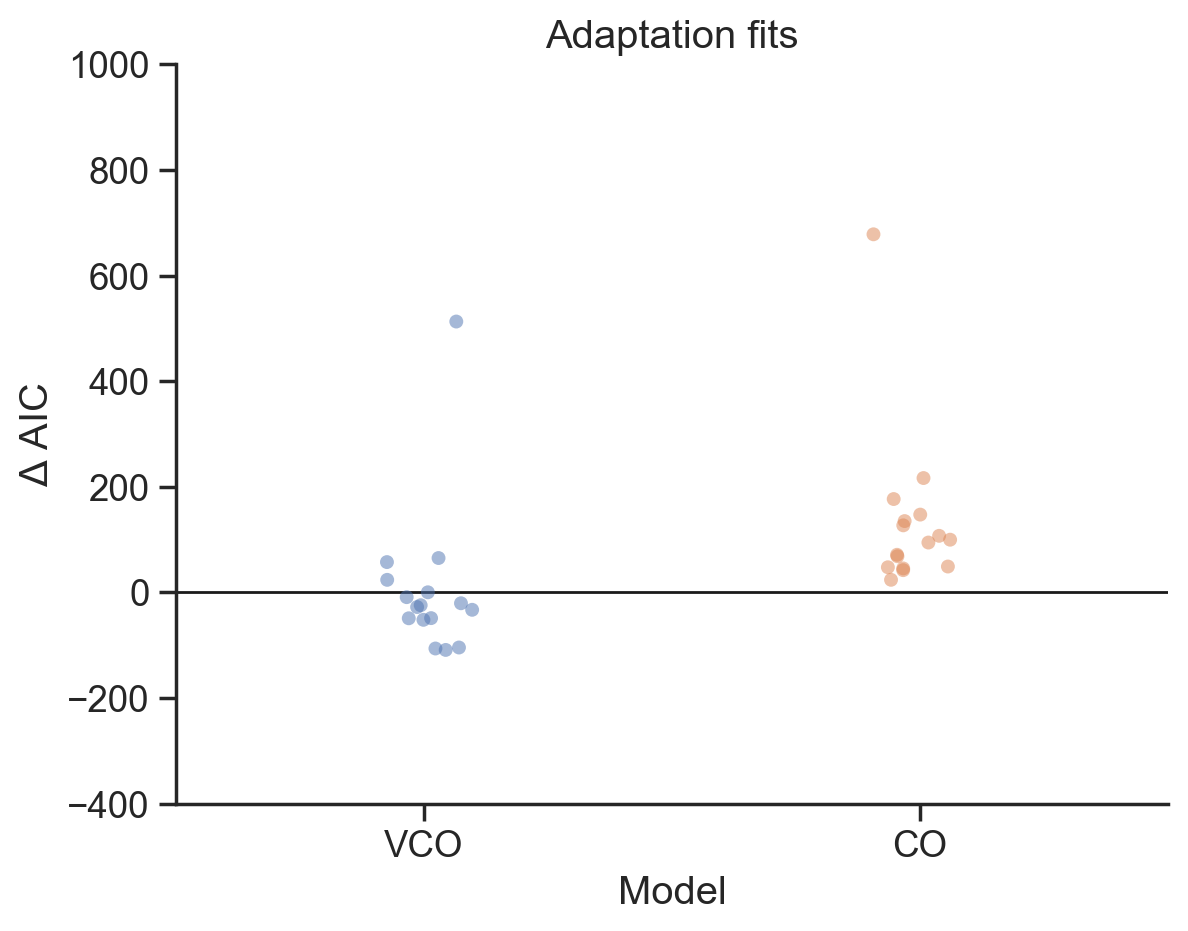

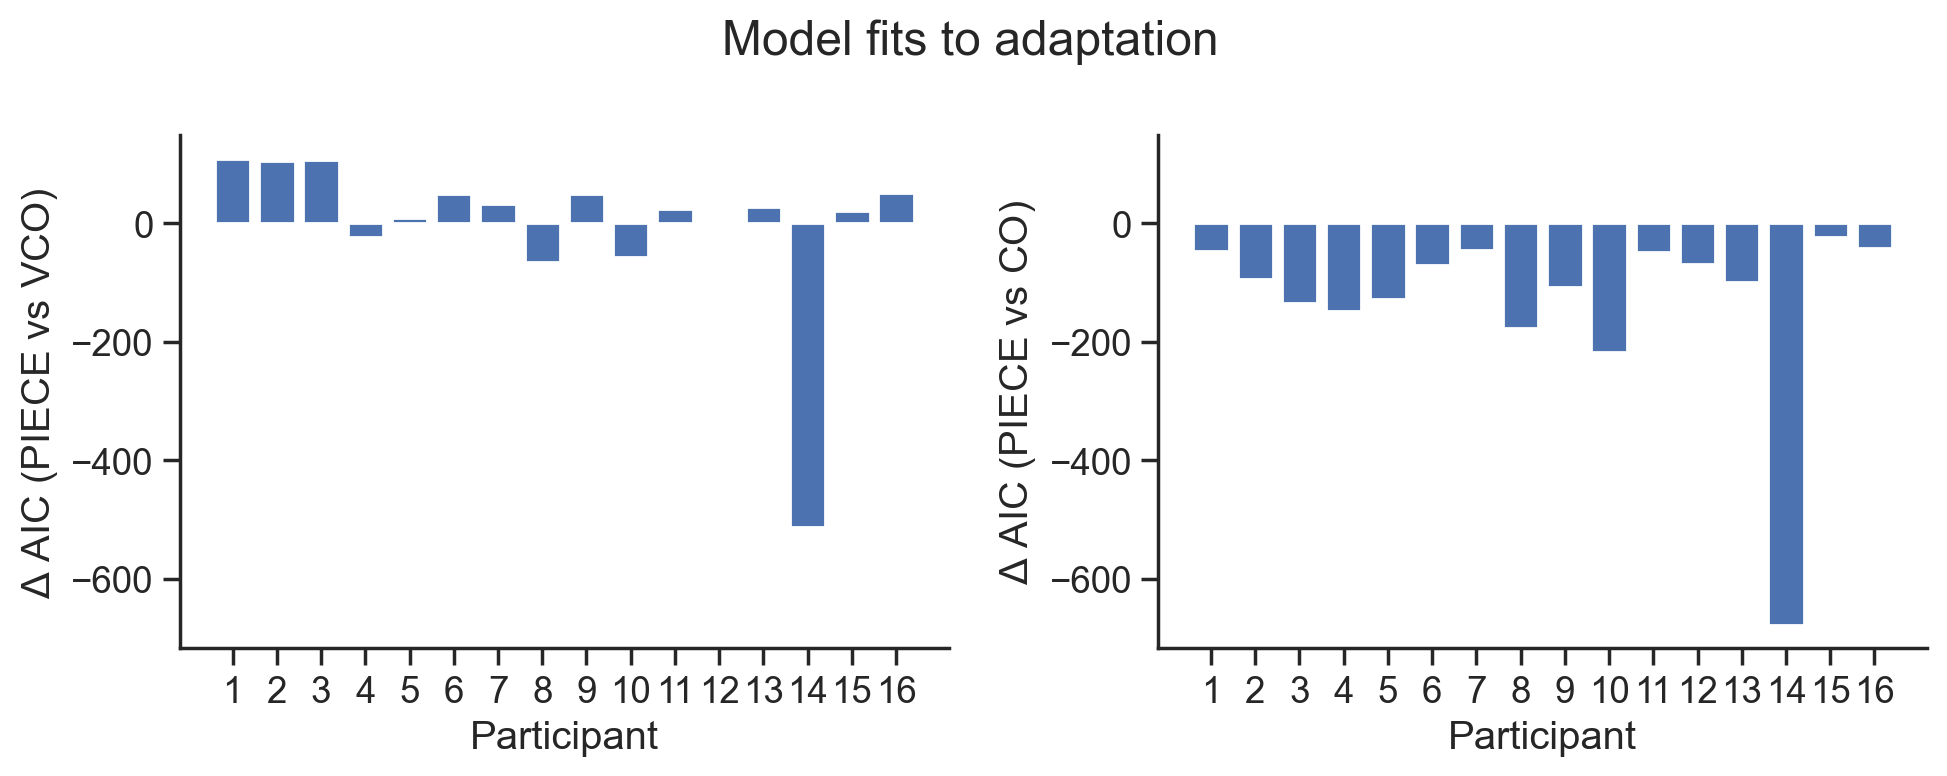

In [7]:
# Compare models on adaptation
fig, ax = plt.subplots()
sns.stripplot(data=fits_adapt, x="model", y="aic_diff_piece", hue="model", ax=ax, alpha=0.5, order=["vco", "co"])
ax.axhline(color="k", linewidth=1.0)
ax.set(xlabel="Model", xticklabels=["VCO", "CO"], ylabel="$\Delta$ AIC", ylim=[-400, 1000])
ax.set_title("Adaptation fits")
sns.despine()
plt.show()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
ax1.bar(x=fits_adapt.loc[idx_vco, "SN"].values, height=fits_adapt.loc[idx_vco, "aic_diff_piece"].values * -1)
ax2.bar(x=fits_adapt.loc[idx_vco, "SN"].values, height=fits_adapt.loc[idx_co, "aic_diff_piece"].values * -1)
ax1.set(xticks=np.arange(1, 17), ylabel="$\Delta$ AIC (PIECE vs VCO)", xlabel="Participant")
ax2.set(ylabel="$\Delta$ AIC (PIECE vs CO)", xlabel="Participant")
ax2.tick_params(labelleft=True)
fig.suptitle("Model fits to adaptation")
sns.despine()
plt.tight_layout()

In [8]:
# Who is doing best/worst?
fits_adapt.groupby(["SN", "model"])["aic_diff_piece"].mean()

SN  model
1   co        47.404026
    piece      0.000000
    vco     -109.138060
2   co        94.246429
    piece      0.000000
    vco     -104.551770
3   co       134.904812
    piece      0.000000
    vco     -106.440120
4   co       147.151154
    piece      0.000000
    vco       23.591730
5   co       126.815382
    piece      0.000000
    vco       -9.189779
6   co        71.058675
    piece      0.000000
    vco      -48.909166
7   co        45.223957
    piece      0.000000
    vco      -33.132807
8   co       176.629817
    piece      0.000000
    vco       64.905041
9   co       106.965186
    piece      0.000000
    vco      -49.223019
10  co       216.395086
    piece      0.000000
    vco       57.227232
11  co        48.826352
    piece      0.000000
    vco      -24.476387
12  co        68.289743
    piece      0.000000
    vco        0.003573
13  co        99.641889
    piece      0.000000
    vco      -27.922073
14  co       678.024577
    piece      0.000000
    vc

In [9]:
# Compare models on sdt task
idx_vco = (fits_sdt["model"] == "vco") 
idx_co = (fits_sdt["model"] == "co") 
idx_piece = (fits_sdt["model"] == "piece") 

# # Compare models to PIECE
# diff_vco = fits_sdt.loc[idx_piece, "aic"].values - fits_sdt.loc[idx_vco, "aic"].values
# diff_co = fits_sdt.loc[idx_piece, "aic"].values - fits_sdt.loc[idx_co, "aic"].values
# diff_piece = fits_sdt.loc[idx_piece, "aic"].values - fits_sdt.loc[idx_piece, "aic"].values
diff_vco = fits_sdt.loc[idx_piece, "aic_weighted"].values - fits_sdt.loc[idx_vco, "aic_weighted"].values
diff_co = fits_sdt.loc[idx_piece, "aic_weighted"].values - fits_sdt.loc[idx_co, "aic_weighted"].values
diff_piece = fits_sdt.loc[idx_piece, "aic_weighted"].values - fits_sdt.loc[idx_piece, "aic_weighted"].values

fits_sdt["aic_diff_piece"] = np.nan
fits_sdt.loc[idx_vco, "aic_diff_piece"] = diff_vco
fits_sdt.loc[idx_co, "aic_diff_piece"] = diff_co
fits_sdt.loc[idx_piece, "aic_diff_piece"] = diff_piece
fits_sdt.head()

,SN,model,fit_task,nll,aic,bic,params,C,sigma_v,b,sigma_comb,alpha,beta,sigma_p,sigma_pert,aic_weighted,bic_weighted,aic_diff_piece
0,1,vco,sdt,318.538186,643.076371,657.122697,"[3.41250859, 1.82921363, -0.11052107]",3.412509,1.829214,-0.110521,NaN,NaN,NaN,NaN,NaN,935.269293,950.448146,-59.923817
1,2,vco,sdt,286.700472,579.400945,593.447271,"[5.1097239, 2.46265332, 2.78463823]",5.109724,2.462653,2.784638,NaN,NaN,NaN,NaN,NaN,843.107896,858.289325,-47.516307
2,3,vco,sdt,466.611546,939.223091,953.189412,"[3.46698499, 3.8885529, 0.20789672]",3.466985,3.888553,0.207897,NaN,NaN,NaN,NaN,NaN,1309.749891,1324.719279,63.349744
3,4,vco,sdt,367.046285,740.092570,754.142653,"[4.10714784, 2.64430312, 0.25845051]",4.107148,2.644303,0.258451,NaN,NaN,NaN,NaN,NaN,1071.766434,1086.934960,-61.414966
4,5,vco,sdt,266.566256,539.132513,553.178838,"[4.82265147, 2.26528203, 0.07786751]",4.822651,2.265282,0.077868,NaN,NaN,NaN,NaN,NaN,783.651936,798.830789,-6.990012


/var/folders/42/fy648srd41l966jbjlswhljc0000gr/T/ipykernel_75328/599264711.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set(xlabel="Model", xticklabels=["VCO", "CO"], ylabel="$\Delta$ AIC", ylim=[-300, 100])


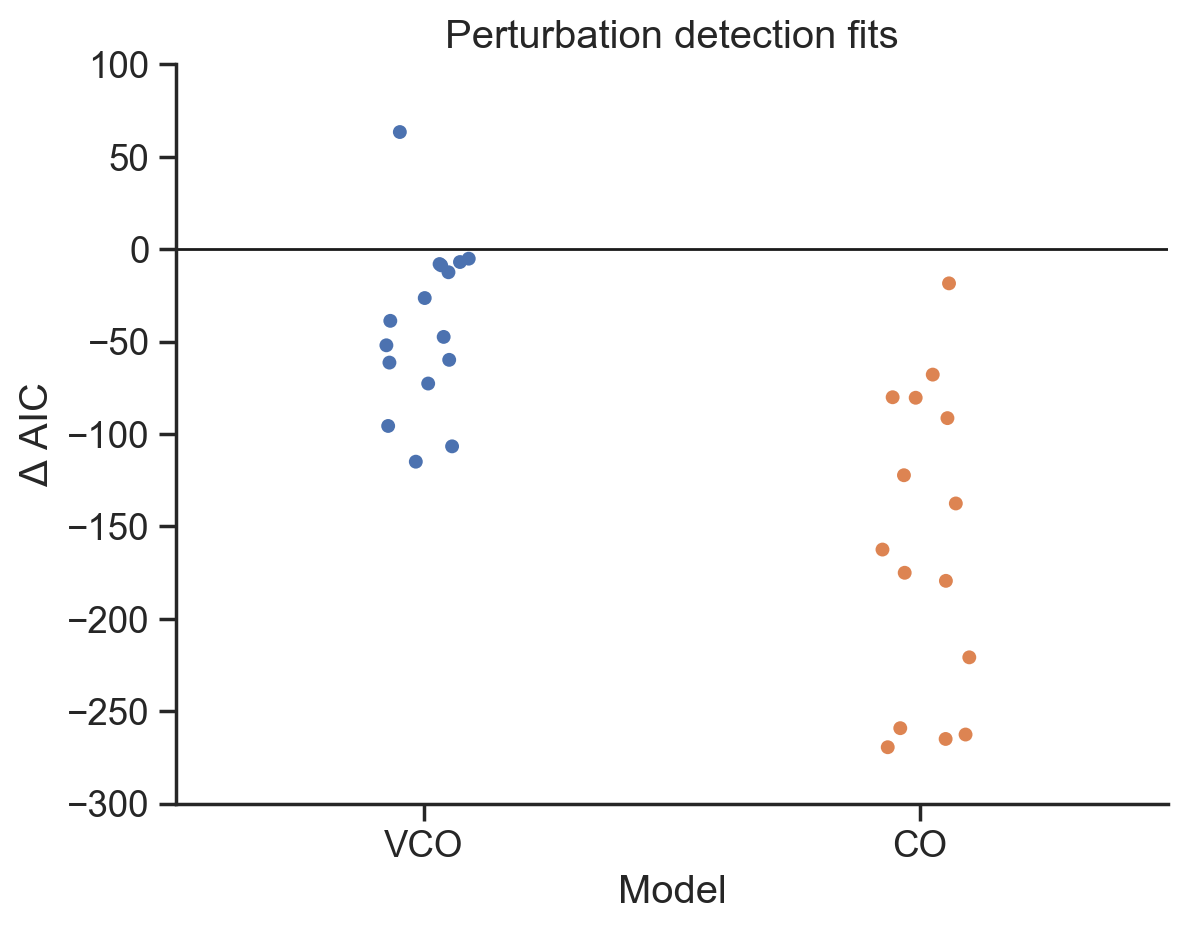

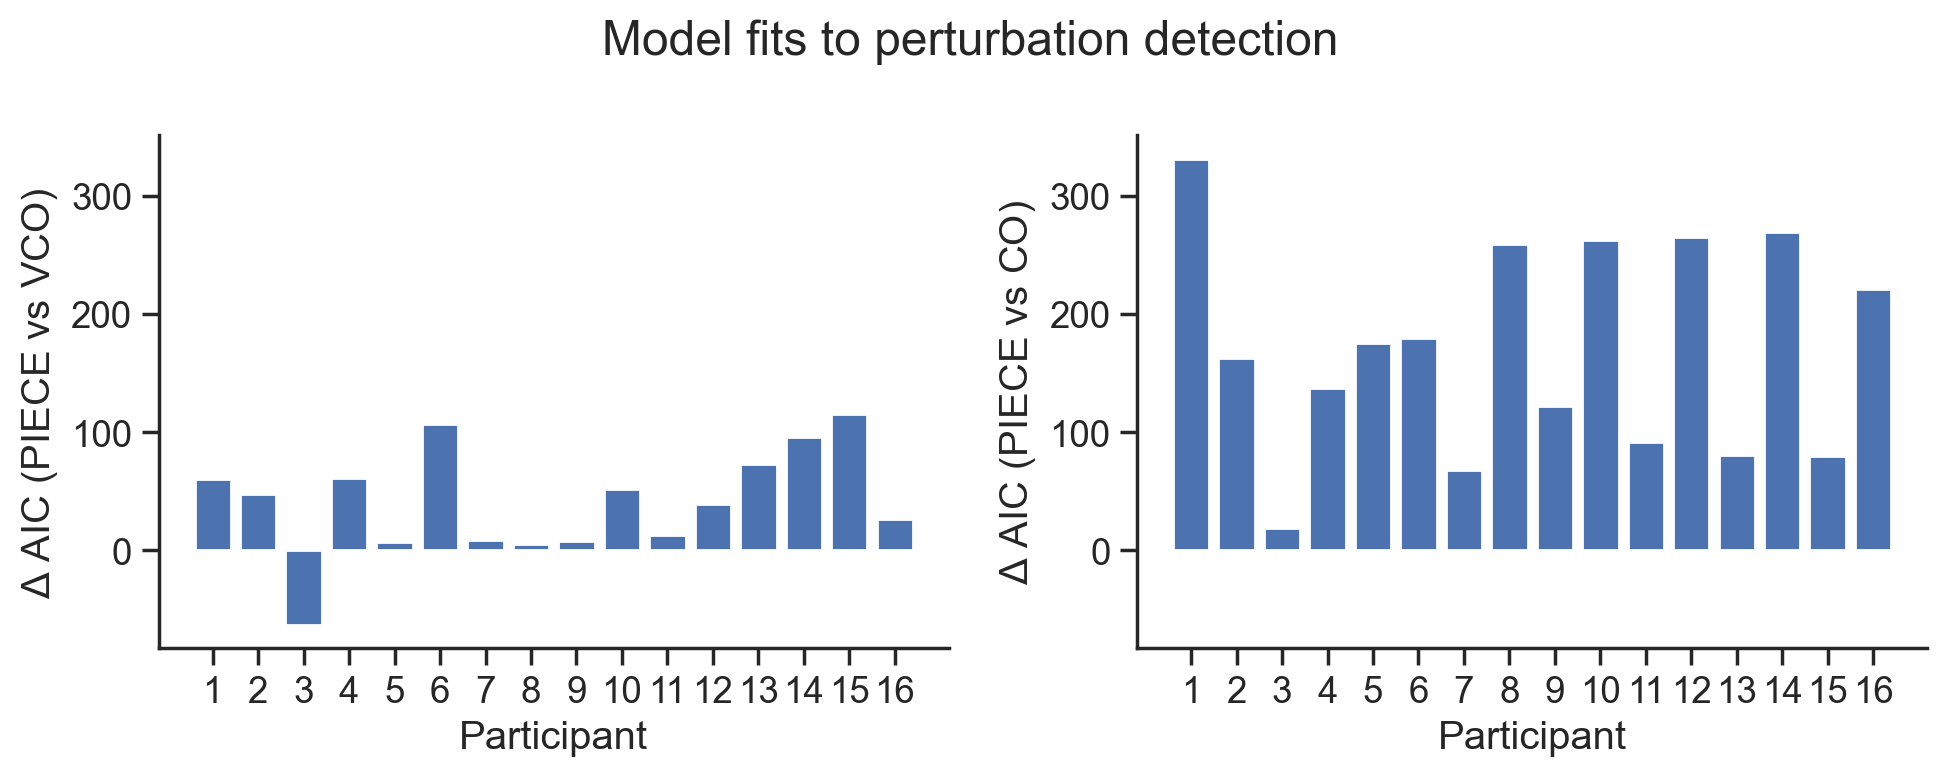

In [10]:
# Compare models on sdt
fig, ax = plt.subplots()
sns.stripplot(data=fits_sdt, x="model", y="aic_diff_piece", hue="model", ax=ax, order=["vco", "co"])
ax.axhline(color="k", linewidth=1.0)
ax.set(xlabel="Model", xticklabels=["VCO", "CO"], ylabel="$\Delta$ AIC", ylim=[-300, 100])
ax.set_title("Perturbation detection fits")
sns.despine()
plt.show()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
ax1.bar(x=np.arange(1, 17), height=fits_sdt.loc[idx_vco, "aic_diff_piece"].values * -1)
ax2.bar(x=np.arange(1, 17), height=fits_sdt.loc[idx_co, "aic_diff_piece"].values * -1)
ax1.set(xticks=np.arange(1, 17), ylabel="$\Delta$ AIC (PIECE vs VCO)", xlabel="Participant")
ax2.set(ylabel="$\Delta$ AIC (PIECE vs CO)", xlabel="Participant")
ax2.tick_params(labelleft=True)
fig.suptitle("Model fits to perturbation detection")
sns.despine()
plt.tight_layout()
sns.despine()

In [11]:
# Who's winning?
fits_sdt.groupby(["SN", "model"])["aic_diff_piece"].mean()

SN  model
1   co      -331.432088
    piece      0.000000
    vco      -59.923817
2   co      -162.585146
    piece      0.000000
    vco      -47.516307
3   co       -18.536129
    piece      0.000000
    vco       63.349744
4   co      -137.642203
    piece      0.000000
    vco      -61.414966
5   co      -175.147822
    piece      0.000000
    vco       -6.990012
6   co      -179.514469
    piece      0.000000
    vco     -106.734825
7   co       -67.916433
    piece      0.000000
    vco       -8.789017
8   co      -259.240504
    piece      0.000000
    vco       -5.179636
9   co      -122.363899
    piece      0.000000
    vco       -8.085547
10  co      -262.678738
    piece      0.000000
    vco      -52.057934
11  co       -91.465933
    piece      0.000000
    vco      -12.529601
12  co      -265.076281
    piece      0.000000
    vco      -38.819202
13  co       -80.442559
    piece      0.000000
    vco      -72.747452
14  co      -269.548074
    piece      0.000000
    vc

---
## Posterior Predictive Plots

In [12]:
# Read in data 
df_behav = pd.read_csv("combined-data.csv")
df_behav.head(10)

,si,SN,id,tester,TN,move_cycle,hX,hY,rot_hX,rot_hY,...,pert_trial,x_f_z,x_f_outlier,no_fit,x_f_mean,x_f_clean,adaptation,sigma_motor_adapt,pert_resp,sigma_motor_sdt
0,1,1,01_i,s,101,101,-6.523699,95.708669,0.0,0.0,...,True,-1.121559,False,False,1.541759,-1.606234,0.983717,2.246088,NaN,NaN
1,1,1,01_i,s,102,102,-0.073699,96.518669,0.0,0.0,...,False,0.036549,False,False,1.541759,1.624840,0.000000,2.246088,NaN,NaN
2,1,1,01_i,s,103,103,-3.833699,93.848669,0.0,0.0,...,True,-0.591950,False,False,1.541759,-0.128646,0.581988,2.246088,NaN,NaN
3,1,1,01_i,s,104,104,0.466301,92.658669,0.0,0.0,...,False,0.245150,False,False,1.541759,2.206829,0.000000,2.246088,NaN,NaN
4,1,1,01_i,s,105,105,-0.043699,90.888669,0.0,0.0,...,True,-0.011512,False,False,1.541759,1.490751,0.870253,2.246088,NaN,NaN
5,1,1,01_i,s,106,106,2.096301,91.888669,0.0,0.0,...,False,0.557073,False,False,1.541759,3.077081,0.000000,2.246088,NaN,NaN
6,1,1,01_i,s,107,107,0.256301,94.218669,0.0,0.0,...,True,-0.305145,False,False,1.541759,0.671527,-0.190481,2.246088,NaN,NaN
7,1,1,01_i,s,108,108,0.906301,95.168669,0.0,0.0,...,False,0.488799,False,False,1.541759,2.886601,0.000000,2.246088,NaN,NaN
8,1,1,01_i,s,109,109,2.026301,93.148669,0.0,0.0,...,True,1.663108,False,False,1.541759,6.162874,-5.025827,2.246088,NaN,NaN
9,1,1,01_i,s,110,110,-4.003699,93.218669,0.0,0.0,...,False,-1.312598,False,False,1.541759,-2.139226,0.000000,2.246088,NaN,NaN


In [13]:
# Choose a sample subject
subj_id = 1
sample_subj = df_behav.loc[(df_behav["SN"] == subj_id) & (df_behav["session"] == "adapt"), :].reset_index(drop=True)
sigma_motor = sample_subj.loc[0, "sigma_motor_adapt"]

# Pull out best-fit adaptation params for chosen subject:
vco_mles = fits_adapt.loc[fits_adapt["model"] == "vco", ["C", "B", "sigma_v", "b"]]
co_mles = fits_adapt.loc[fits_adapt["model"] == "co", ["C", "B", "sigma_comb", "b"]]
piece_mles = fits_adapt.loc[fits_adapt["model"] == "piece", ["alpha", "beta", "sigma_p", "sigma_pert", "b"]]

# Pull out best-fit sdt params
vco_mles_sdt = fits_sdt.loc[fits_sdt["model"] == "vco", ["C", "sigma_v", "b"]]
co_mles_sdt = fits_sdt.loc[fits_sdt["model"] == "co", ["C", "sigma_comb", "b"]]
piece_mles_sdt = fits_sdt.loc[fits_sdt["model"] == "piece", ["alpha", "beta", "sigma_p", "sigma_pert", "b"]]

In [30]:
# Simulate adaptation with best-fit parameters
# VCO model
xhat_vco = vco_simulate_adapt(
    df=sample_subj,
    C=vco_mles["C"].values[0], 
    B=vco_mles["B"].values[0],
    sigma_v=vco_mles["sigma_v"].values[0],
    b=vco_mles["b"].values[0],
)
# Need to match number of simulated adapt measures without importing last bsl trial
xhat_vco = np.insert(xhat_vco, 0, np.random.normal(loc=vco_mles["b"].values[0], scale=sigma_motor))  
adapt_vco = xhat_vco[2::2] - xhat_vco[0:-1:2]

# CO model
xhat_co = co_simulate_adapt(
    df=sample_subj,
    C=co_mles["C"].values[0], 
    B=co_mles["B"].values[0],
    sigma_comb=co_mles["sigma_comb"].values[0],
    b=co_mles["b"].values[0],
    sigma_plan=0
)
# Need to match number of simulated adapt measures without importing last bsl trial
xhat_co = np.insert(xhat_co, 0, np.random.normal(loc=co_mles["b"].values[0], scale=sigma_motor))  
adapt_co = xhat_co[2::2] - xhat_co[0:-1:2]

# PIECE model
xhat_piece = piece_simulate_adapt(
    df=sample_subj,
    alpha=piece_mles["alpha"].values[0], 
    beta=piece_mles["beta"].values[0],
    sigma_p=piece_mles["sigma_p"].values[0],
    sigma_pert=piece_mles["sigma_pert"].values[0],
    b=piece_mles["b"].values[0],
)
# Need to match number of simulated adapt measures without importing last bsl trial
xhat_piece = np.insert(xhat_piece, 0, np.random.normal(loc=piece_mles["b"].values[0], scale=sigma_motor))  
adapt_piece = xhat_piece[2::2] - xhat_piece[0:-1:2]


# # CO-hybrid model w increasing visual uncertainty
# xhat_cohyb = cohybrid_simulate_adapt(
#     df=sample_subj,
#     C=1, 
#     B=0.35,
#     alpha=0.75,
#     beta=0.9,
#     b=0.3,
#     sigma_p=4
# )
# # Need to match number of simulated adapt measures without importing last bsl trial
# xhat_cohyb = np.insert(xhat_cohyb, 0, np.random.normal(loc=co_mles["b"].values[0], scale=sigma_motor))  
# adapt_cohyb = xhat_cohyb[2::2] - xhat_cohyb[0:-1:2]

In [31]:
# Find perturbation trials in data frame
pert_indices = np.flatnonzero(sample_subj["pert_trial"])

# Trim subject data frame to only adaptation trials
df_trimmed = sample_subj.loc[pert_indices, :]
SN = df_trimmed.loc[:, "SN"]
rotation = df_trimmed.loc[:, "delta_xv"]

# Create data frame with all perturbation trials
df_plot = pd.DataFrame({
    "delta_xv" : df_trimmed.loc[:, "delta_xv"],
    "adaptation" : df_trimmed.loc[:, "adaptation"],
    "x_f" : df_trimmed.loc[:, "x_f_clean"],
    "xhat_vco" : xhat_vco[1::2],
    "adapt_vco" : adapt_vco,
    "xhat_co" : xhat_co[1::2],
    "adapt_co" : adapt_co,
    "xhat_piece" : xhat_piece[1::2], 
    "adapt_piece" : adapt_piece, 
    "rotation" : rotation,
    "SN" : SN
})


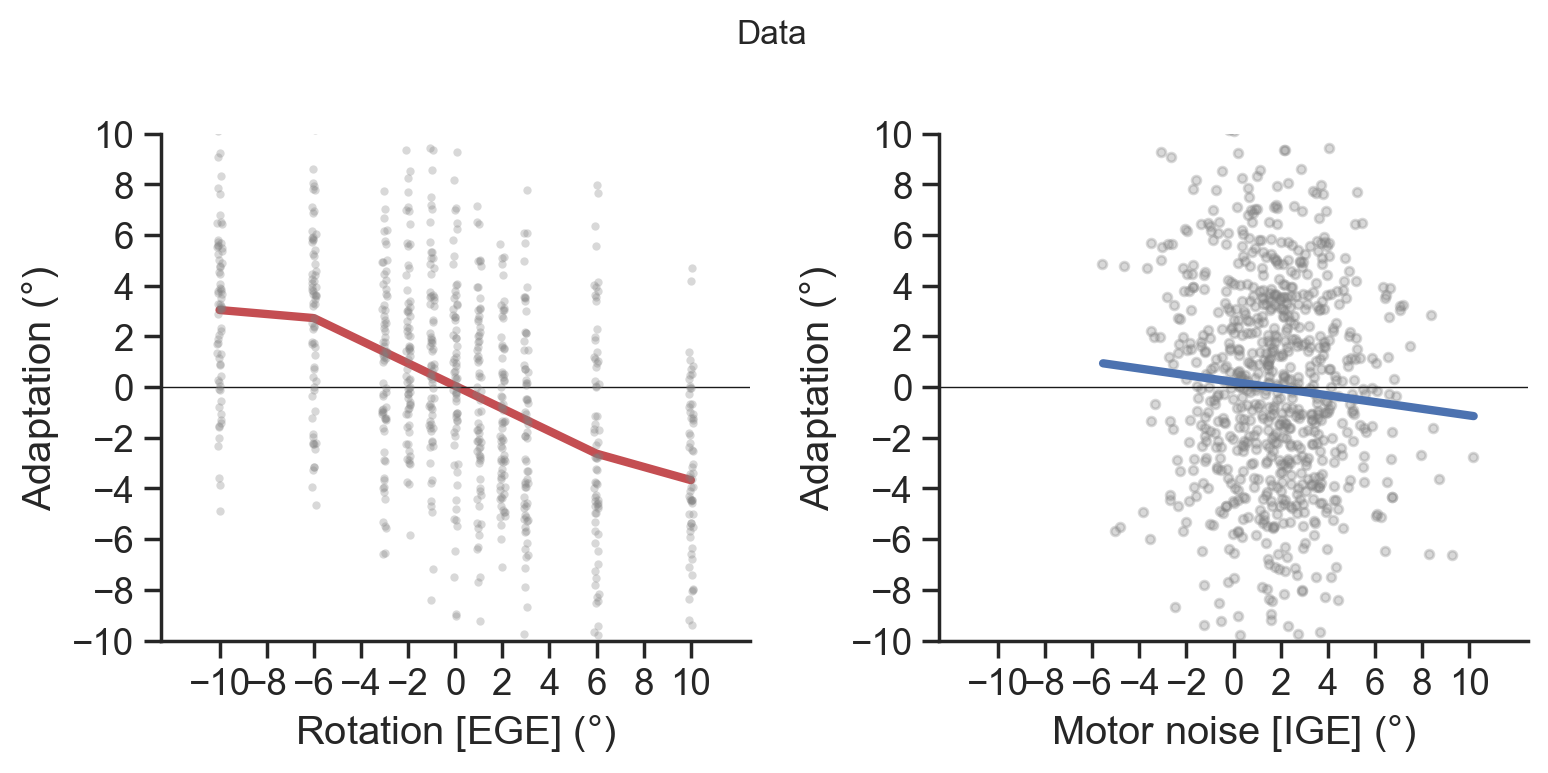

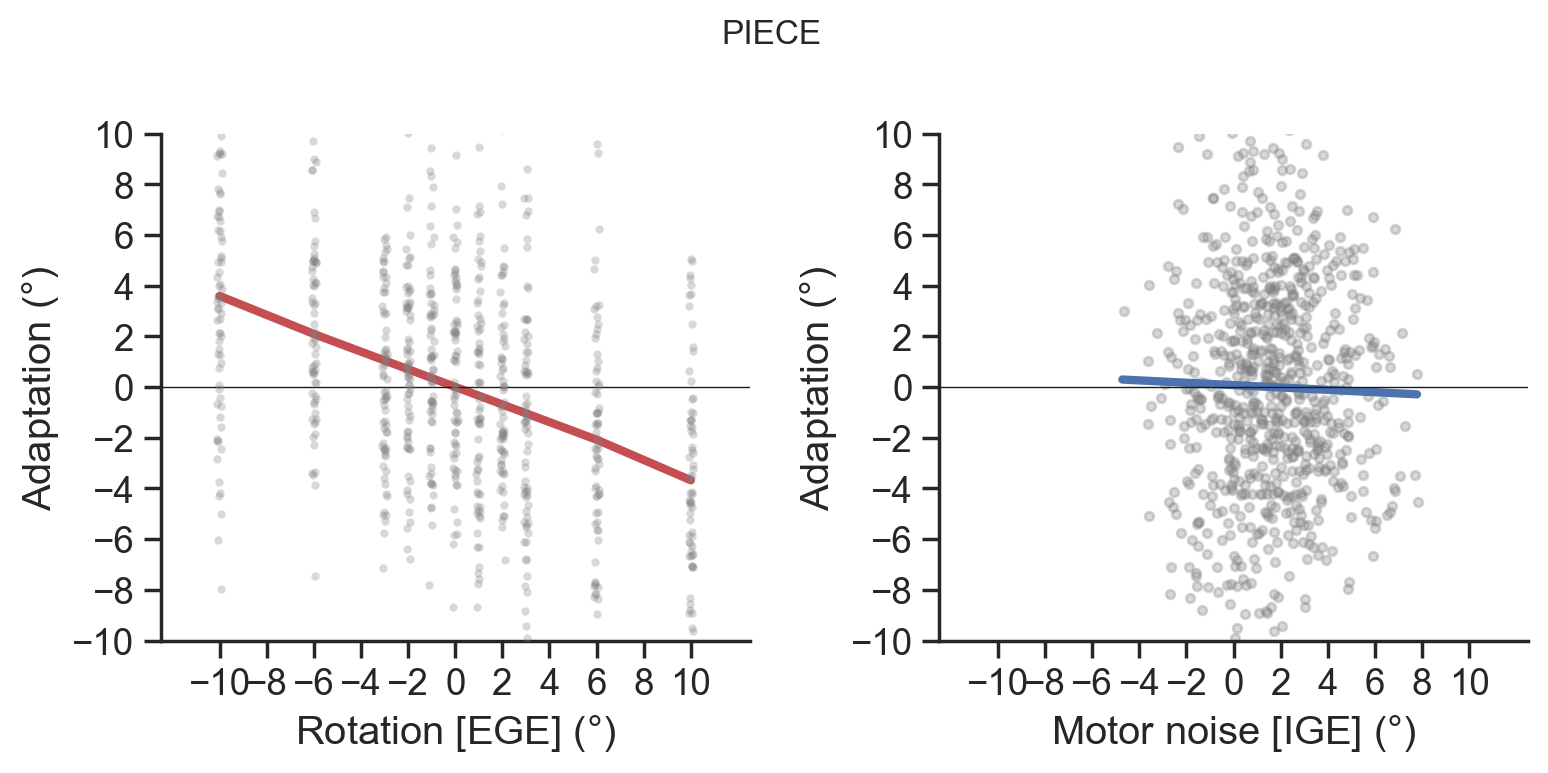

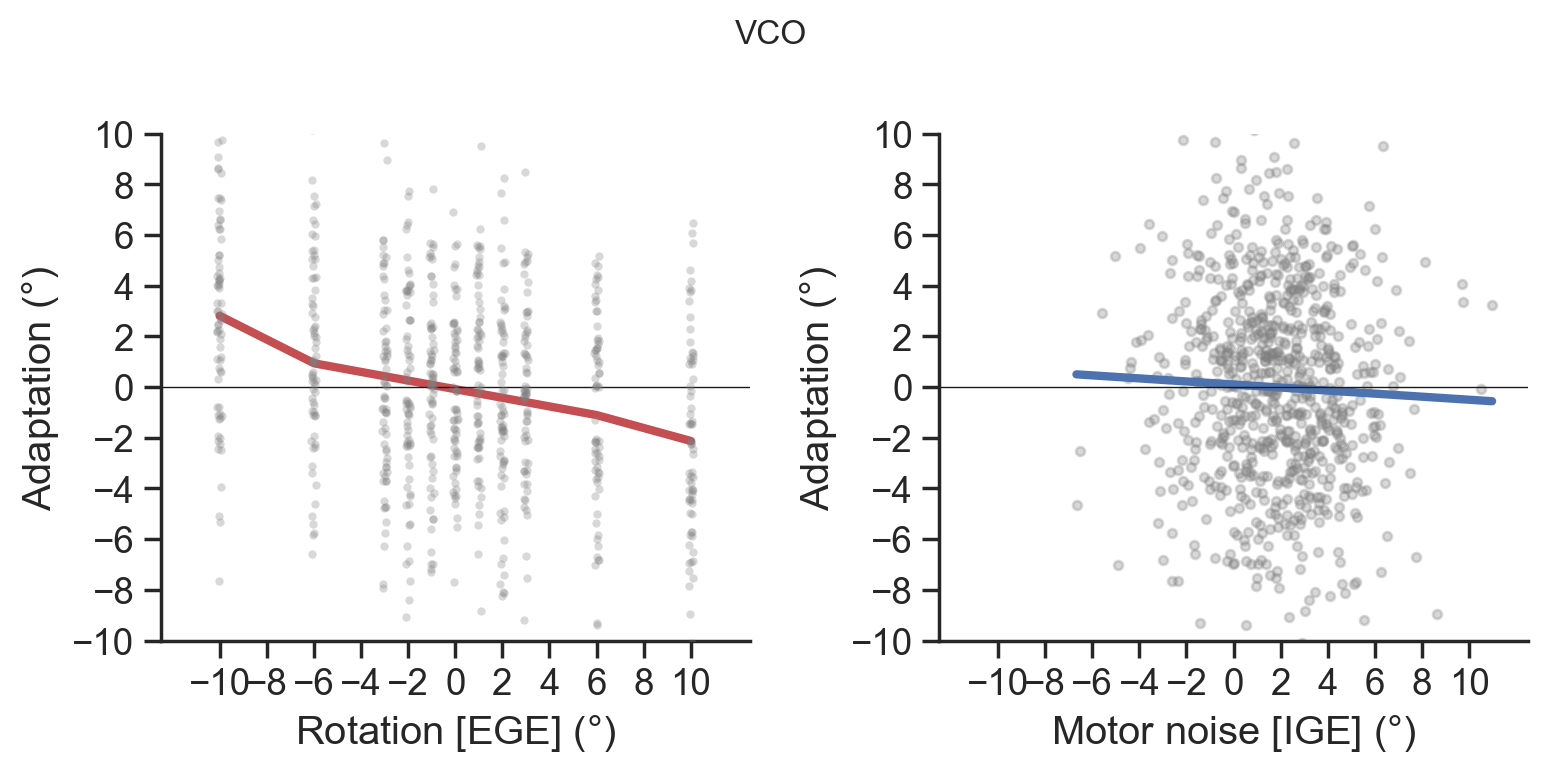

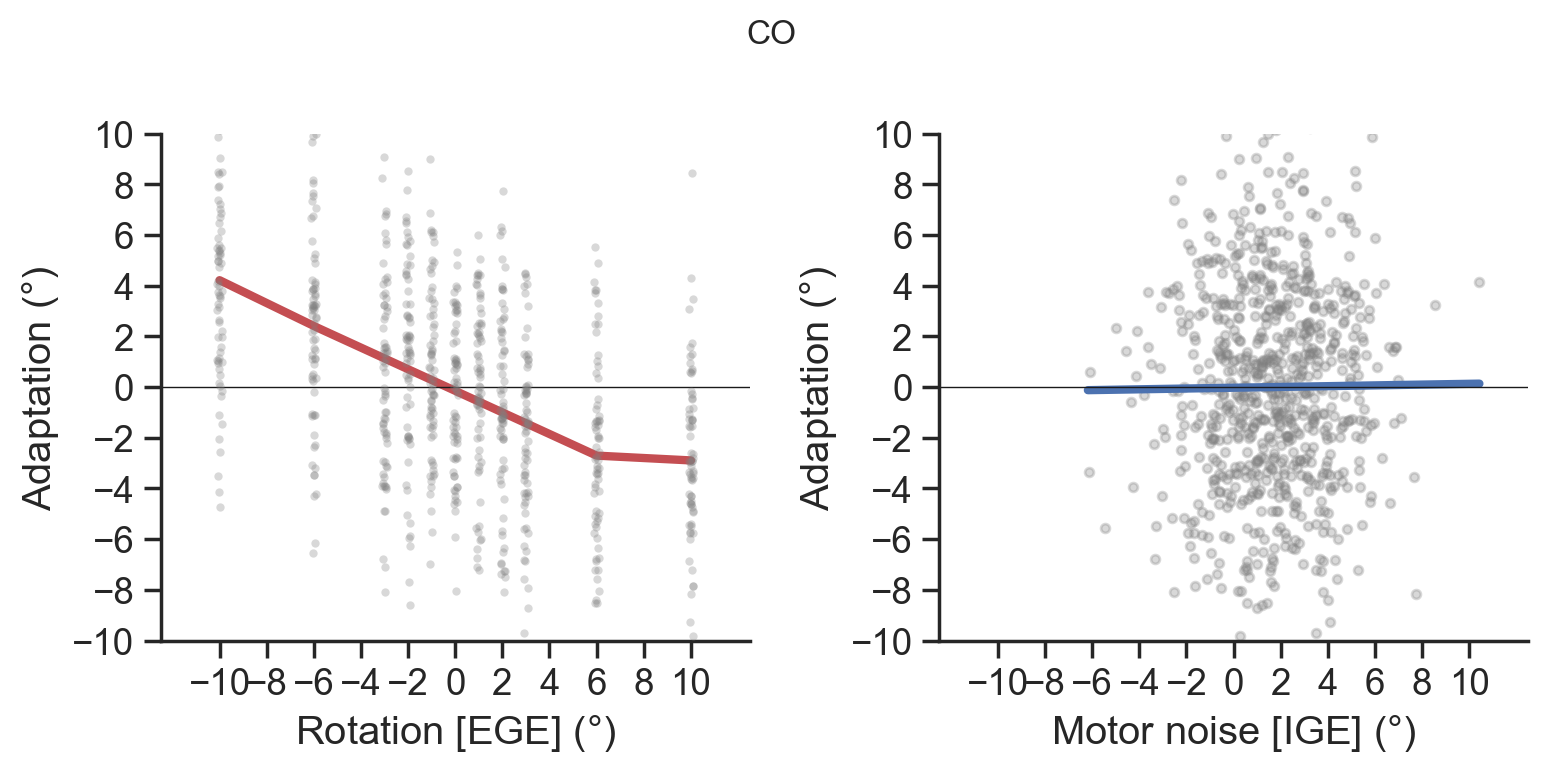

In [32]:
# Set up a list of your matrices and titles to loop through easily
titles = ['Data', 'PIECE', 'VCO', 'CO']
sim_x_f = [df_plot["x_f"], df_plot["xhat_piece"], df_plot["xhat_vco"], df_plot["xhat_co"]]
sim_adapt = [df_plot["adaptation"], df_plot["adapt_piece"], df_plot["adapt_vco"], df_plot["adapt_co"]]

# Loop through each subplot axis and data matrix
for i in range(len(titles)):
    df_vmr = pd.DataFrame({"SN": SN, "reaches": sim_x_f[i], "adaptation": sim_adapt[i], "rotation": rotation}) 

    # Create a 4-row, 1-column layout that shares the X-axis across all plots
    fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(8, 4))
    
    # Fit EGE-adaptation data with breakpoint regression
    x_fit, y_fit, _, _, _, _ = fit_piecewise_with_ci(df_vmr, _, xcol="rotation", ycol="adaptation", 
                                                                        bp1=6, bp2=-6, n_points=300, alpha=0.05)
    
    # Plot data for adapt vs vmr-ege
    # fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 3.5))
    sns.stripplot(data=df_vmr, x="rotation", y="adaptation", color="gray", alpha=0.3, s=3, native_scale=True, ax=ax1)
    ax1.plot(x_fit, y_fit, c="r", linewidth=3)
    ax1.axhline(0, c="k", linewidth=0.5)
    ax1.set(xticks=np.arange(-10, 10.1, 2), yticks=np.arange(-10, 10.1, 2), xlabel="Rotation [EGE] ($\degree$)", 
            xlim=(-12.5, 12.5), ylim=(-10, 10), ylabel="Adaptation ($\degree$)")
    sns.despine()
    
    # Plot data for adapt vs ige
    sns.regplot(data=df_vmr, x="reaches", y="adaptation", x_jitter=0.1, 
               line_kws=dict(linewidth=3), scatter_kws=dict(alpha=0.3, color='gray', s=10), ci=0, ax=ax2)
    ax2.set(xticks=np.arange(-10, 10.1, 2), yticks=np.arange(-10, 10.1, 2), xlabel="Motor noise [IGE] ($\degree$)", 
            xlim=(-12.5, 12.5), ylim=(-10, 10), ylabel="Adaptation ($\degree$)")
    ax2.axhline(0, c="k", linewidth=0.5)
    
    fig.suptitle(titles[i], fontsize=12)

    sns.despine()
    plt.tight_layout()


In [17]:
# Simulate sdt with best-fit parameters
sdt_subj = df_behav.loc[(df_behav["SN"] == subj_id) & (df_behav["session"] == "sdt"), :].reset_index(drop=True)
# VCO model
resp_vco = vco_simulate_sdt(
    df=sdt_subj,
    C=vco_mles_sdt["C"].values[0], 
    sigma_v=vco_mles_sdt["sigma_v"].values[0],
    b=vco_mles_sdt["b"].values[0],
)

# CO model
resp_co = co_simulate_sdt(
    df=sdt_subj,
    C=co_mles_sdt["C"].values[0], 
    sigma_comb=co_mles_sdt["sigma_comb"].values[0],
    b=co_mles_sdt["b"].values[0],
)

# PIECE model
resp_piece = piece_simulate_sdt(
    df=sdt_subj,
    alpha=piece_mles_sdt["alpha"].values[0], 
    beta=piece_mles_sdt["beta"].values[0],
    sigma_p=piece_mles_sdt["sigma_p"].values[0],
    sigma_pert=piece_mles_sdt["sigma_pert"].values[0],
    b=piece_mles_sdt["b"].values[0],
)

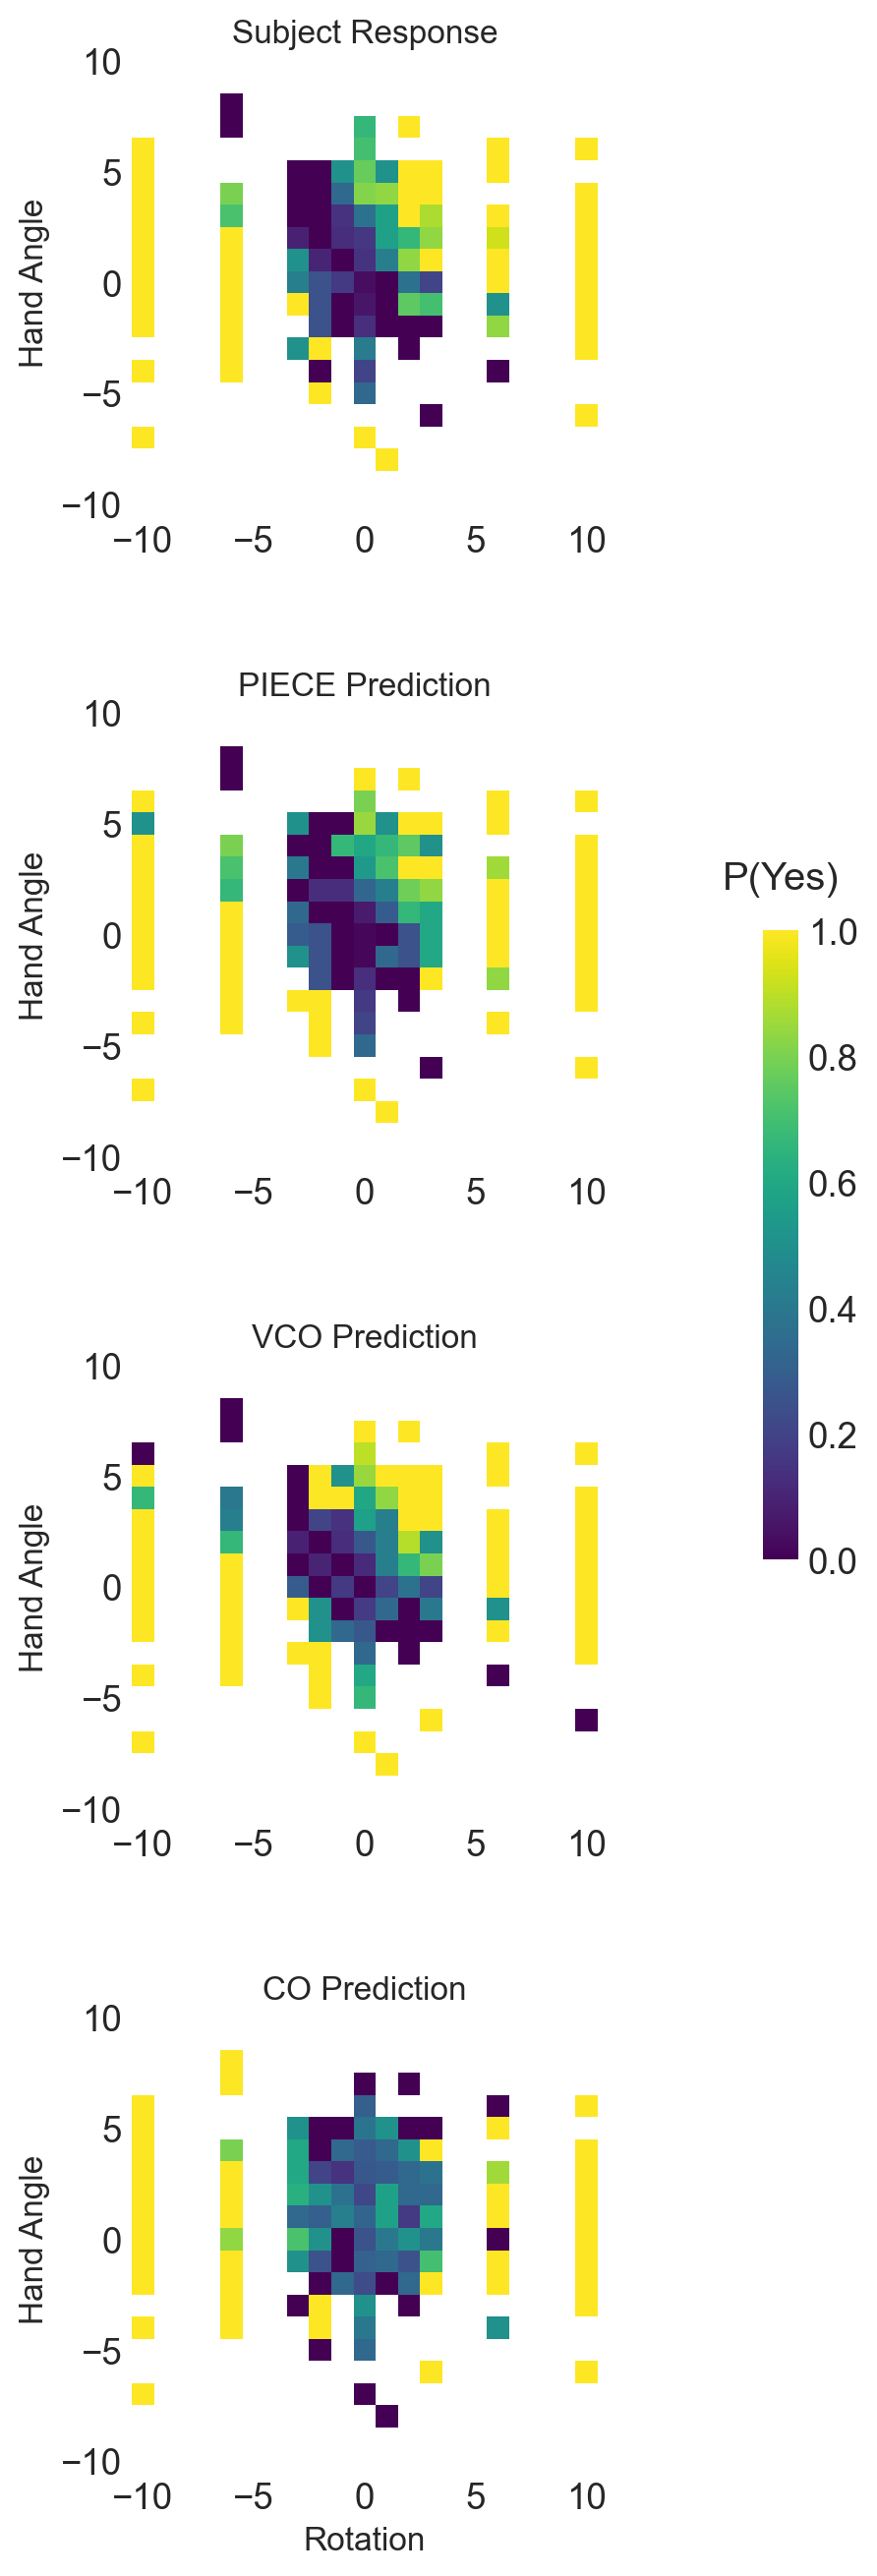

In [18]:
# Create heatmaps of post-predicts 
idx = np.abs(sdt_subj["x_f"].values) <= 10.5  # filter anomalous trials for visualization
x_hand = sdt_subj.loc[idx, "x_f"].values
rotation = sdt_subj.loc[idx, "delta_xv"].values
subj_resp = sdt_subj.loc[idx, "pert_resp"].values
vco_resp = resp_vco[idx]
co_resp = resp_co[idx]
piece_resp = resp_piece[idx]

sdt_postpred = pd.DataFrame({
    "x_hand" : np.round(x_hand),
    "rotation" : rotation,
    "subj_resp" : subj_resp,
    "vco_resp" : vco_resp,
    "co_resp" : co_resp,
    "piece_resp" : piece_resp
})

# Create 2D pivot tables (matrices) for plotting
subj_mat = sdt_postpred.pivot_table(index="x_hand", columns="rotation", values="subj_resp", aggfunc="mean").sort_index(ascending=False)
vco_mat = sdt_postpred.pivot_table(index="x_hand", columns="rotation", values="vco_resp", aggfunc="mean").sort_index(ascending=False)
co_mat = sdt_postpred.pivot_table(index="x_hand", columns="rotation", values="co_resp", aggfunc="mean").sort_index(ascending=False)
piece_mat = sdt_postpred.pivot_table(index="x_hand", columns="rotation", values="piece_resp", aggfunc="mean").sort_index(ascending=False)

# Create uniform sequence for rotation var so that we don't get stretched out rectangles in heatmap
uniform_rotation_steps = np.arange(-10, 11, step=1) 

# Reindex columns of matrices to use a perfect grid.
# Skipped cols get filled with NaNs.
subj_mat = subj_mat.reindex(columns=uniform_rotation_steps)
vco_mat = vco_mat.reindex(columns=uniform_rotation_steps)
co_mat = co_mat.reindex(columns=uniform_rotation_steps)
piece_mat = piece_mat.reindex(columns=uniform_rotation_steps)

# Set up a list of matrices and titles to loop through easily
matrices = [subj_mat, piece_mat, vco_mat, co_mat]
titles = ['Subject Response','PIECE Prediction', 'VCO Prediction', 'CO Prediction']

fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(6, 16))

# Loop through each subplot axis and data matrix
for i, ax in enumerate(axes):
    mat = matrices[i]
    
    # Extract coordinates uniform data structures
    x_coords = mat.columns.values
    y_coords = mat.index.values
    z_values = mat.values
    
    # Render heatmaps
    mesh = ax.pcolormesh(
        x_coords, y_coords, z_values, 
        shading='nearest', 
        cmap='viridis',
        vmin=0, vmax=1  # Lock color scale from 0% to 100% across all maps
    )
    
    ax.set_aspect('equal')
    
    # Remove all spines
    for spine in ['top', 'bottom', 'left', 'right']:
        ax.spines[spine].set_visible(False)
        
    # Remove ticks
    ax.tick_params(axis='both', which='both', length=0)
    
    # More esthetics
    ax.set_ylabel('Hand Angle', fontsize=12) 
    ax.set_title(titles[i], fontsize=12, pad=0)
    ax.set_xlim(-10.5, 10.5)
    ax.set_xticks([-10, -5, 0, 5, 10])
    ax.set_ylim(-10.5, 10.5)  
    ax.set_yticks([-10, -5, 0, 5, 10])

# Only add the x-axis label to bottom plot
axes[-1].set_xlabel('Rotation', fontsize=12)
# axes[-1].set_xticks([-10, -6, -3, -2, -1, 0, 1, 2, 3, 6, 10]) 

# Shared colorbar on the right side of the vertical stack
cbar_ax = fig.add_axes([0.85, 0.40, 0.03, 0.20])  # left, bottom, width, height
cbar = fig.colorbar(mesh, cax=cbar_ax)
# cbar.set_label('P(Yes)', loc="top", )
cbar.ax.set_title('P(Yes)', pad=15)

# Clean up the colorbar borders and ticks
cbar.outline.set_visible(False)
cbar.ax.tick_params(length=0)

# Adjust layout space vertically (hspace) so titles don't crash into the plot above them
plt.subplots_adjust(right=0.90, hspace=0.4)
plt.show()
